In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from lib_pca.utils_sqrtm import sqrtm
from lib_pca.utils_plot import draw_cov
from lib_pca.lifted_pca import LiftedPCA
from lib_pca.uncertainty_aware_pca import UAPCA

[KeOps] Warning : CUDA libraries not found or could not be loaded; Switching to CPU only.


In [2]:
def plot(eig_lifted, eig_distr_pca, samples, means, Sigmas, title=None, weights=None, bary_lifted_pca=None):

    if weights is None:
        weights = np.ones(len(eig_lifted))
    weights = np.asarray(weights, dtype=float)

    max_weight = weights.max()
    if max_weight > 0:
        # Scale by the absolute maximum to avoid exaggerating tiny differences.
        alpha = 0.2 + 0.8 * weights / max_weight
        alpha = np.clip(alpha, 0.0, 1.0)
    else:
        alpha = np.ones_like(weights)

    index_max_alpha = np.argmax(alpha)

    for k in range(len(samples)):
        plt.scatter(samples[k][:, 0], samples[k][:,1], alpha=0.1)
        draw_cov(means[k], Sigmas[k], nstd=1)
    
    plt.scatter(means[:, 0], means[:, 1], marker="x", s=100, c="k")
    
    ts = torch.linspace(-5, 5, 100)

    if bary_lifted_pca is not None:
        pc = ts[:,None] * bary_lifted_pca[0][None]
        plt.plot(pc[:,0], pc[:,1], c="orange", lw=2, label="Barycenter Lifted PCA")

    pc = ts[:,None] * eig_distr_pca[:,0][None]
    plt.plot(pc[:,0], pc[:,1], c="black", label="UAPCA")
    
    for k in range(len(eig_lifted)):
        pc = ts[:,None] * eig_lifted[k,:,0][None]
        line_kwargs = {
            "c": "orange",
            "alpha": alpha[k],
            "lw": 0.8 + alpha[k],
            "zorder": 3,
        }

        if k == index_max_alpha:
            line_kwargs.update({"lw": 2.2, "label": "Lifted PCA"})

        plt.plot(pc[:,0], pc[:,1], **line_kwargs)

    if title is not None:
        plt.title(title)

    plt.legend()
    
    plt.xlim(-5, 5)
    plt.ylim(-5, 5)
    plt.show()

## Example of Niculae

In [3]:
## Data from https://arxiv.org/abs/2306.13503

m1, m2, m3, m4 = [-0.5, -2], [0.5, -1], [-0.5, 0], [0.5, 1]
means = torch.tensor([m1, m2, m3, m4])

Sigma = torch.diag(torch.tensor([1, 0.5]))
Sigmas = torch.stack([Sigma for i in range(len(means))])

n = 1000
d = 2
samples = torch.zeros((len(means), n, d))
for k in range(len(means)):
    samples[k] = means[k] + torch.randn(n, d) @ sqrtm(Sigmas[k])

INFO:2026-09-10 10:41:34,397:jax._src.xla_bridge:812: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
INFO: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory


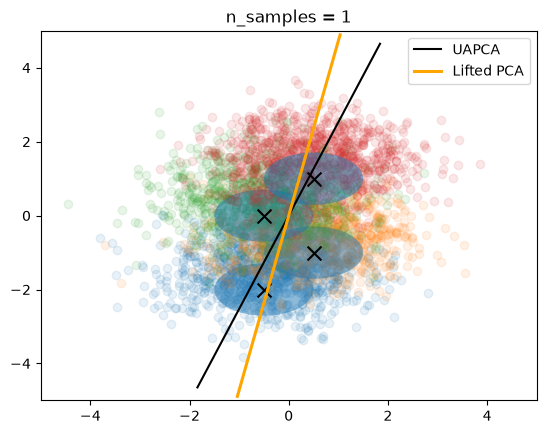

n=1 LiftedPCA 1.15972558278902 UAPCA 1.140311808936844
tensor([[-0.0011, -0.5014]]) tensor([[-0.0011, -0.5014]])


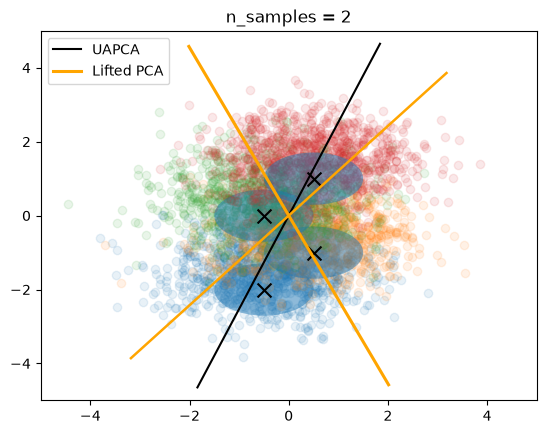

n=2 LiftedPCA 0.505514272018059 UAPCA 1.140311808936844
tensor([[-0.0011, -0.5014]]) tensor([[-0.0011, -0.5014]])


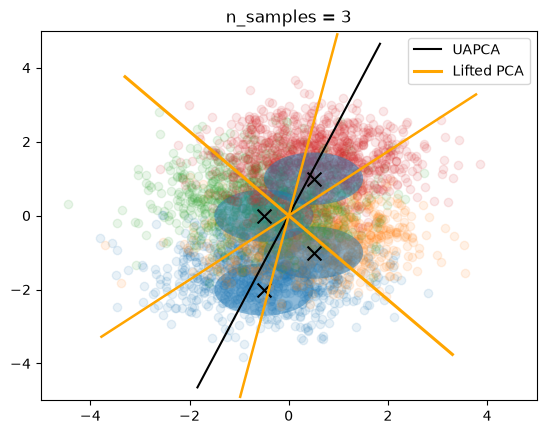

n=3 LiftedPCA 0.2952269190458044 UAPCA 1.140311808936844
tensor([[-0.0011, -0.5014]]) tensor([[-0.0011, -0.5014]])


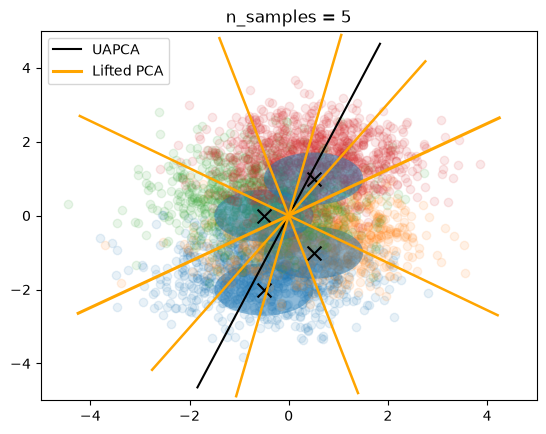

n=5 LiftedPCA 0.1575890863822741 UAPCA 1.140311808936844
tensor([[-0.0011, -0.5014]]) tensor([[-0.0011, -0.5014]])


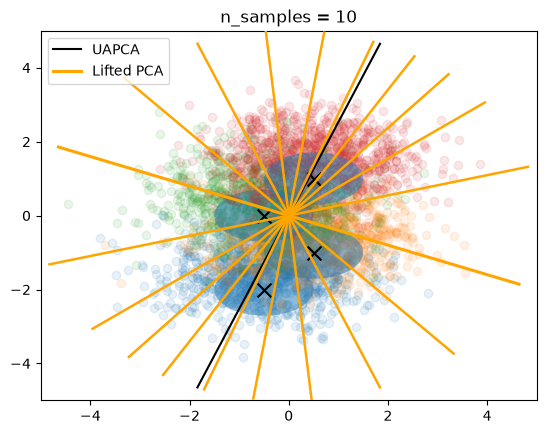

n=10 LiftedPCA 0.08255502749437539 UAPCA 1.140311808936844
tensor([[-0.0011, -0.5014]]) tensor([[-0.0011, -0.5014]])


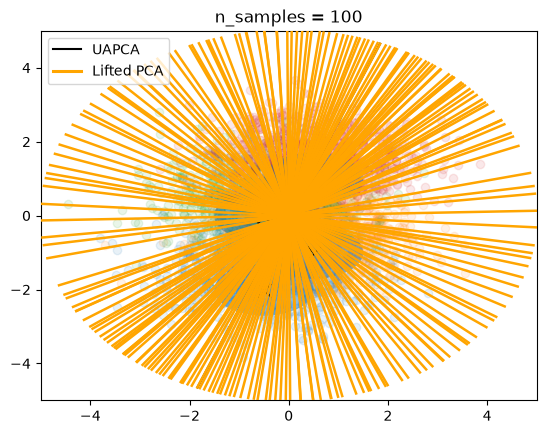

n=100 LiftedPCA 0.05701944377732332 UAPCA 1.140311808936844
tensor([[-0.0011, -0.5014]]) tensor([[-0.0011, -0.5014]])


In [4]:
# Vary number of Dirac
for n_samples in [1, 2, 3, 5, 10, 100]:
    lifted_pca = LiftedPCA(n_components=1, n_samples=n_samples)
    lifted_pca.fit(samples)
    eigenvectors_lifted = lifted_pca.components_
    
    # Distributional PCA
    pca_distributional = UAPCA()
    pca_distributional.fit_from_samples(samples)
    eigenvectors_distributional = pca_distributional.components_# .numpy()

    plot(eigenvectors_lifted, eigenvectors_distributional, lifted_pca.center_data(samples), means, Sigmas, title="n_samples = "+str(n_samples))

    print(
        "n="+str(n_samples), "LiftedPCA", lifted_pca.cost_barycenter(samples).item(),
        "UAPCA", pca_distributional.cost_barycenter(samples).item()
    )

    print(lifted_pca.mean_, pca_distributional.mean_)

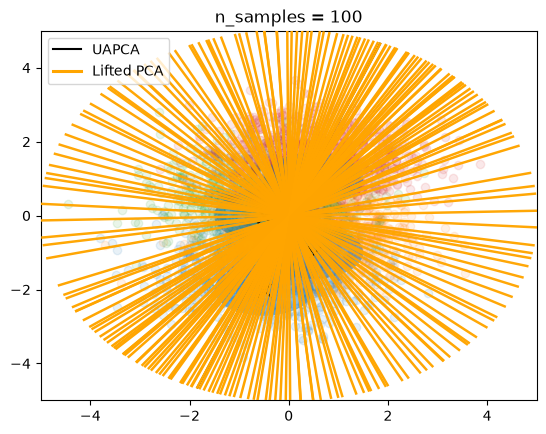

Barycenter cost: 0.05758994358312501


In [5]:
# Fix the support and optim over weights only (with good initialization)
lifted_pca = LiftedPCA(n_components=1, n_samples=100)
lifted_pca.fit(samples, eigenvectors_lifted, solver="fixed_support", seed=42, n_iter_bary=1000, stop_threshold_fixed_support=1e-20)
eigenvectors_lifted = lifted_pca.components_

# Distributional PCA
pca_distributional = UAPCA()
pca_distributional.fit_from_samples(samples)
eigenvectors_distributional = pca_distributional.components_# .numpy()

plot(eigenvectors_lifted, eigenvectors_distributional, lifted_pca.center_data(samples), means, Sigmas,
     title="n_samples = "+str(100), weights=lifted_pca.weights_.numpy())

print("Barycenter cost:", lifted_pca.cost_barycenter(samples).item())

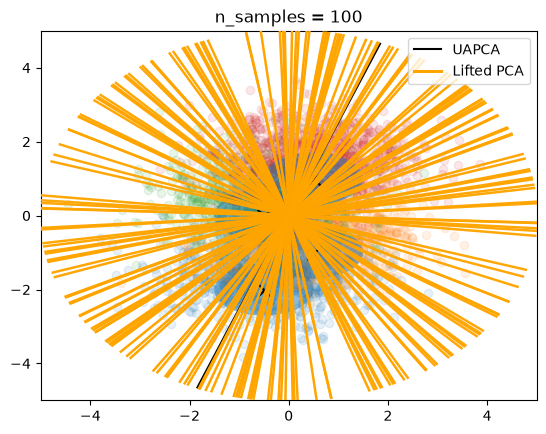

Barycenter cost: 0.07173625169848398


In [6]:
# Fix the support and optim over weights only
lifted_pca = LiftedPCA(n_components=1, n_samples=100)
lifted_pca.fit(samples, solver="fixed_support", seed=42, n_iter_bary=1000, stop_threshold_fixed_support=1e-20)
eigenvectors_lifted = lifted_pca.components_

# Distributional PCA
pca_distributional = UAPCA()
pca_distributional.fit_from_samples(samples)
eigenvectors_distributional = pca_distributional.components_# .numpy()

plot(eigenvectors_lifted, eigenvectors_distributional, lifted_pca.center_data(samples), means, Sigmas,
     title="n_samples = "+str(100), weights=lifted_pca.weights_.numpy())

print("Barycenter cost:", lifted_pca.cost_barycenter(samples).item())

In [7]:
lifted_pca.weights_

tensor([0.0101, 0.0098, 0.0101, 0.0101, 0.0101, 0.0100, 0.0101, 0.0098, 0.0101,
        0.0100, 0.0101, 0.0101, 0.0101, 0.0099, 0.0101, 0.0101, 0.0101, 0.0099,
        0.0099, 0.0099, 0.0100, 0.0101, 0.0101, 0.0101, 0.0101, 0.0099, 0.0098,
        0.0101, 0.0100, 0.0099, 0.0101, 0.0100, 0.0100, 0.0100, 0.0099, 0.0099,
        0.0100, 0.0098, 0.0101, 0.0101, 0.0101, 0.0098, 0.0099, 0.0098, 0.0101,
        0.0101, 0.0099, 0.0101, 0.0101, 0.0101, 0.0100, 0.0098, 0.0100, 0.0101,
        0.0101, 0.0101, 0.0098, 0.0101, 0.0098, 0.0098, 0.0099, 0.0101, 0.0099,
        0.0098, 0.0098, 0.0099, 0.0098, 0.0100, 0.0100, 0.0099, 0.0099, 0.0101,
        0.0101, 0.0099, 0.0098, 0.0101, 0.0098, 0.0101, 0.0101, 0.0100, 0.0100,
        0.0099, 0.0101, 0.0100, 0.0101, 0.0099, 0.0100, 0.0101, 0.0101, 0.0100,
        0.0101, 0.0101, 0.0100, 0.0101, 0.0099, 0.0098, 0.0100, 0.0098, 0.0101,
        0.0101])

In [8]:
print(lifted_pca.weights_.max().item(), lifted_pca.weights_.min().item())

0.010147741607147171 0.009802233709781519


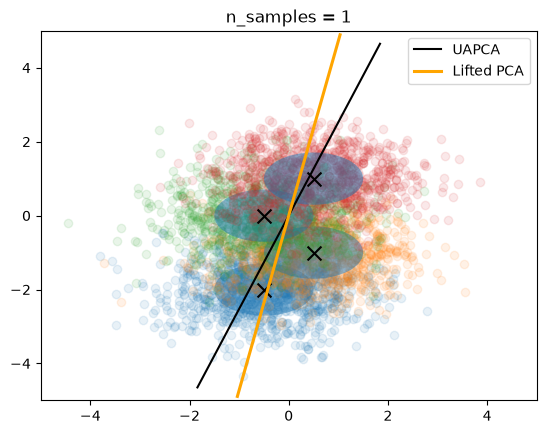

n=1 Lifted 1.15972558278902 Distributional 1.140311808936844
[1.]


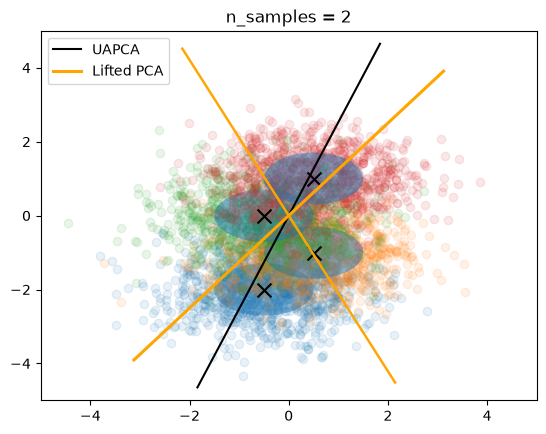

n=2 Lifted 0.5046656557848774 Distributional 1.140311808936844
[0.504484 0.495516]


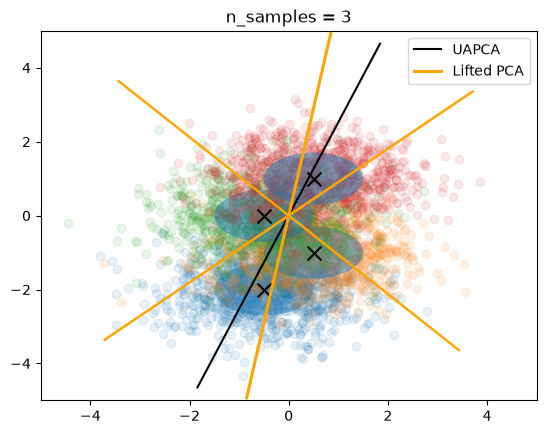

n=3 Lifted 0.2946995638392986 Distributional 1.140311808936844
[0.32796639 0.33535888 0.33667474]


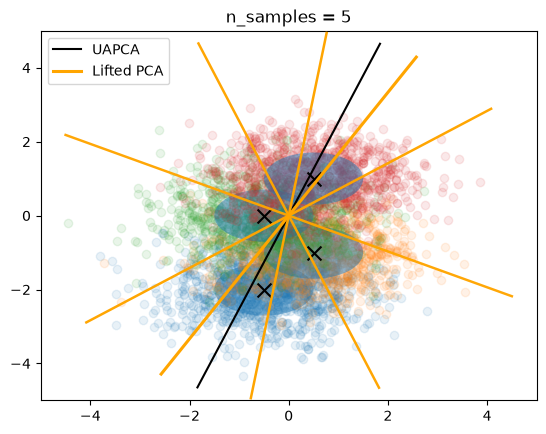

n=5 Lifted 0.15688671130535353 Distributional 1.140311808936844
[0.19558772 0.20209089 0.20061009 0.19939236 0.20231894]


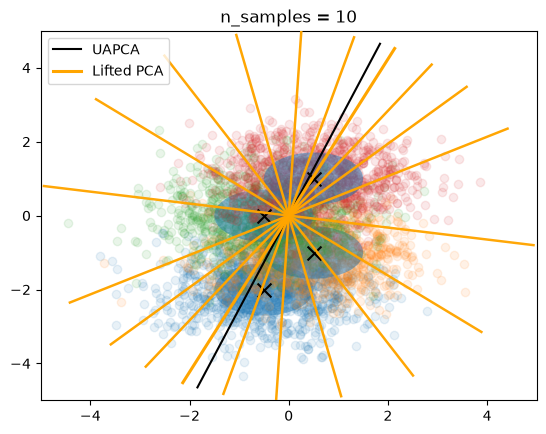

n=10 Lifted 0.0852843666842994 Distributional 1.140311808936844
[0.10067514 0.10111892 0.10102093 0.10082482 0.09791177 0.09916083
 0.10016843 0.10116161 0.09811116 0.09984639]


In [9]:
# Vary number of Dirac, optim over weights and support
for n_samples in [1, 2, 3, 5, 10]:
    lifted_pca = LiftedPCA(n_components=1, n_samples=n_samples)
    lifted_pca.fit(samples, solver="free")
    eigenvectors_lifted = lifted_pca.components_
    
    # Distributional PCA
    pca_distributional = UAPCA()
    pca_distributional.fit_from_samples(samples)
    eigenvectors_distributional = pca_distributional.components_# .numpy()

    plot(eigenvectors_lifted, eigenvectors_distributional, samples, means, Sigmas, title="n_samples = "+str(n_samples),
        weights=lifted_pca.weights_.numpy())

    print(
        "n="+str(n_samples), "Lifted", lifted_pca.cost_barycenter(samples).item(),
        "Distributional", pca_distributional.cost_barycenter(samples).item()
    )

    print(lifted_pca.weights_.numpy())

## 1 Clear PC

In [10]:
n_distr = 100

x0 = torch.zeros((n_distr, 1))
x1 = torch.randn((n_distr, 1))
means = torch.concatenate([x0, x1], axis=1)

# Mean to center full distributions (to be equivalent with PCA)
full_mean = torch.mean(means, axis=0)

# means = torch.randn((4, 2))

Sigma = torch.diag(torch.tensor([0.5, 1.5])) * 0.1
Sigmas = torch.stack([Sigma for i in range(len(means))])

# spd = SPDMatrices(2)
# samples = spd.random_point(n_samples=4)
# Sigmas = torch.from_numpy(samples).type(torch.float)

n = 50
d = 2
samples = torch.zeros((len(means), n, d))
for k in range(len(means)):
    samples[k] = means[k] + torch.randn(n, d) @ sqrtm(Sigmas[k])

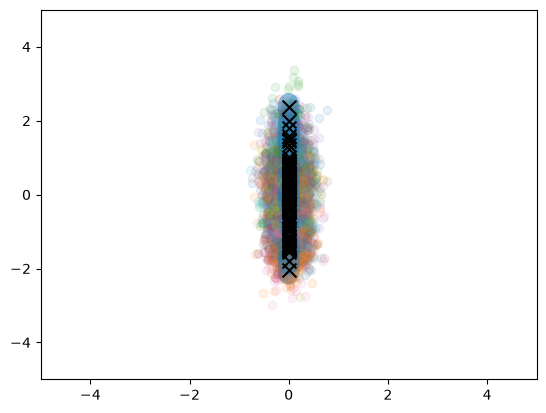

In [11]:
for k in range(len(means)):
    plt.scatter(samples[k][:, 0], samples[k][:,1], alpha=0.1)
    draw_cov(means[k], Sigmas[k], nstd=1)

plt.scatter(means[:, 0], means[:, 1], marker="x", s=100, c="k")

ts = torch.linspace(-5, 5, 100)

# for k in range(len(X_bar2)):
#     pc = ts[:,None] * X_bar2[k,:,0][None]
#     plt.plot(pc[:,0], pc[:,1], c="orange")

plt.xlim(-5, 5)
plt.ylim(-5, 5)
plt.show()

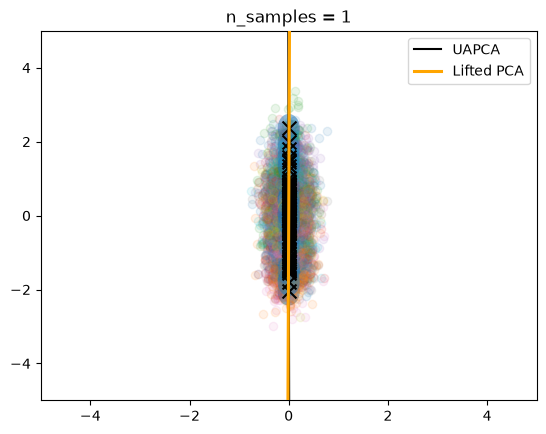

n=1 Lifted 0.050198027796740555 Distributional 0.05017746228955865


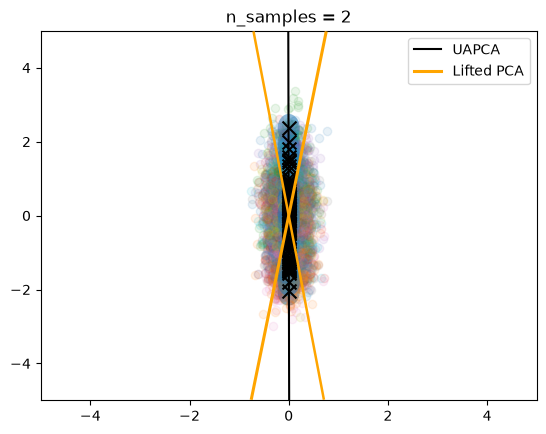

n=2 Lifted 0.029326206416697084 Distributional 0.05017746228955865


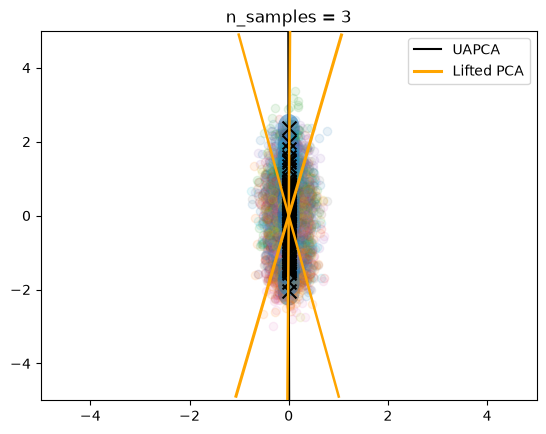

n=3 Lifted 0.023165064189448515 Distributional 0.05017746228955865


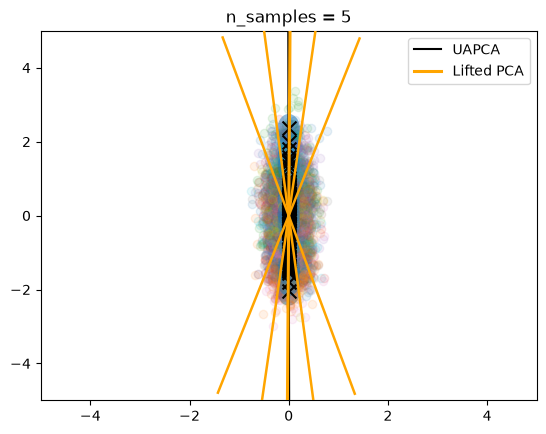

n=5 Lifted 0.018613783844565378 Distributional 0.05017746228955865


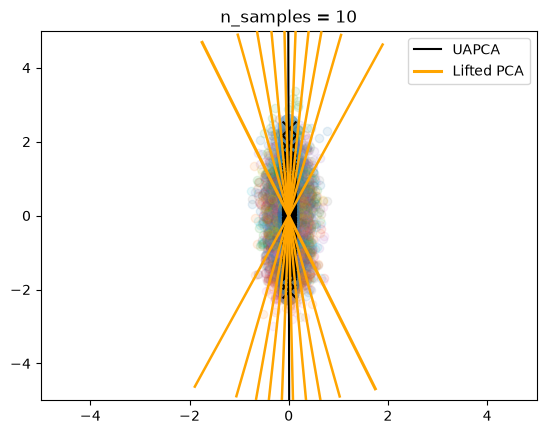

n=10 Lifted 0.015647989081257904 Distributional 0.05017746228955865


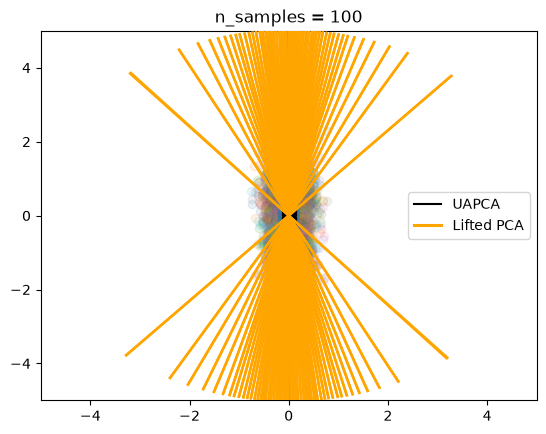

n=100 Lifted 0.013397715994372282 Distributional 0.05017746228955865


In [13]:
# Vary number of Dirac
for n_samples in [1, 2, 3, 5, 10, 100]:
    lifted_pca = LiftedPCA(n_components=1, n_samples=n_samples)
    lifted_pca.fit(samples)
    eigenvectors_lifted = lifted_pca.components_
    
    # Distributional PCA
    pca_distributional = UAPCA()
    pca_distributional.fit_from_samples(samples)
    eigenvectors_distributional = pca_distributional.components_# .numpy()

    plot(eigenvectors_lifted, eigenvectors_distributional, lifted_pca.center_data(samples),
         means, Sigmas, title="n_samples = "+str(n_samples))

    print(
        "n="+str(n_samples), "Lifted", lifted_pca.cost_barycenter(samples).item(),
        "Distributional", pca_distributional.cost_barycenter(samples).item()
    )

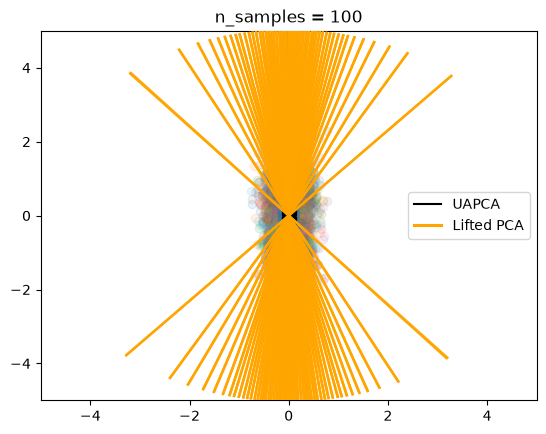

0.013475075633947902


In [15]:
# Fix the support and optim over weights only (with good initialization)
lifted_pca = LiftedPCA(n_components=1, n_samples=100)
lifted_pca.fit(samples, eigenvectors_lifted, solver="fixed_support", n_iter_bary=500, stop_threshold_fixed_support=1e-20)
eigenvectors_lifted = lifted_pca.components_

# Distributional PCA
pca_distributional = UAPCA()
pca_distributional.fit_from_samples(samples)
eigenvectors_distributional = pca_distributional.components_# .numpy()

plot(eigenvectors_lifted, eigenvectors_distributional, lifted_pca.center_data(samples), means, Sigmas,
     title="n_samples = "+str(100), weights=lifted_pca.weights_.numpy())

print(lifted_pca.cost_barycenter(samples).item())

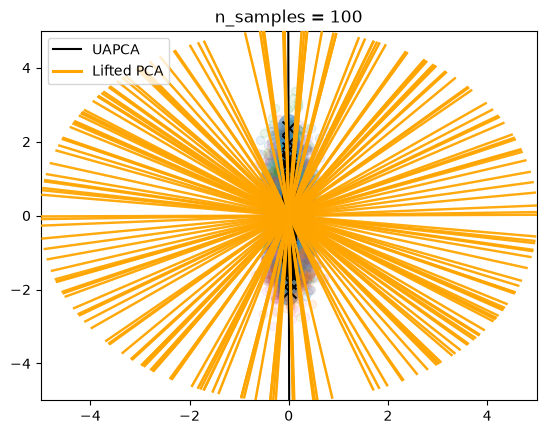

0.19652979907476578


In [16]:
# Fix the support and optim over weights only
lifted_pca = LiftedPCA(n_components=1, n_samples=100)
lifted_pca.fit(samples, solver="fixed_support", lr_bary=0.1, n_iter_bary=500, stop_threshold_fixed_support=1e-20)
eigenvectors_lifted = lifted_pca.components_

# Distributional PCA
pca_distributional = UAPCA()
pca_distributional.fit_from_samples(samples)
eigenvectors_distributional = pca_distributional.components_# .numpy()

plot(eigenvectors_lifted, eigenvectors_distributional, lifted_pca.center_data(samples), means, Sigmas,
     title="n_samples = "+str(100), weights=lifted_pca.weights_.numpy())

print(lifted_pca.cost_barycenter(samples).item())

In [17]:
lifted_pca.weights_

tensor([0.0104, 0.0097, 0.0097, 0.0096, 0.0101, 0.0098, 0.0096, 0.0102, 0.0103,
        0.0104, 0.0096, 0.0102, 0.0104, 0.0101, 0.0102, 0.0097, 0.0096, 0.0097,
        0.0099, 0.0098, 0.0101, 0.0099, 0.0097, 0.0097, 0.0102, 0.0100, 0.0104,
        0.0101, 0.0099, 0.0098, 0.0104, 0.0101, 0.0101, 0.0097, 0.0102, 0.0096,
        0.0098, 0.0098, 0.0097, 0.0096, 0.0098, 0.0104, 0.0100, 0.0097, 0.0104,
        0.0097, 0.0101, 0.0097, 0.0096, 0.0101, 0.0104, 0.0096, 0.0101, 0.0100,
        0.0104, 0.0098, 0.0102, 0.0098, 0.0104, 0.0104, 0.0100, 0.0103, 0.0098,
        0.0099, 0.0103, 0.0099, 0.0104, 0.0104, 0.0096, 0.0098, 0.0097, 0.0096,
        0.0101, 0.0104, 0.0096, 0.0101, 0.0101, 0.0103, 0.0098, 0.0098, 0.0103,
        0.0098, 0.0103, 0.0099, 0.0099, 0.0103, 0.0100, 0.0100, 0.0101, 0.0103,
        0.0103, 0.0100, 0.0104, 0.0103, 0.0100, 0.0097, 0.0101, 0.0104, 0.0096,
        0.0100])

In [18]:
print(lifted_pca.weights_.max(), lifted_pca.weights_.min())

tensor(0.0104) tensor(0.0096)


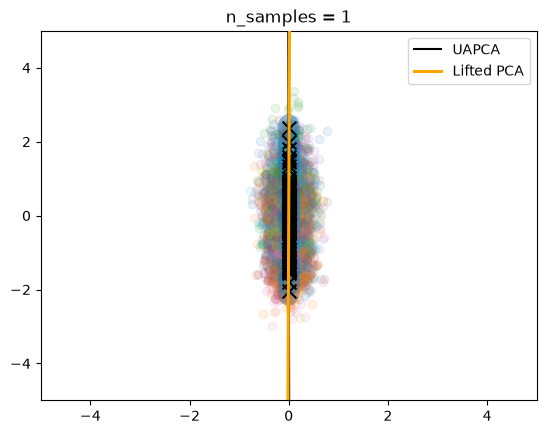

n=1 Lifted 0.050198027796740555 Distributional 0.05017746228955865
[1.]


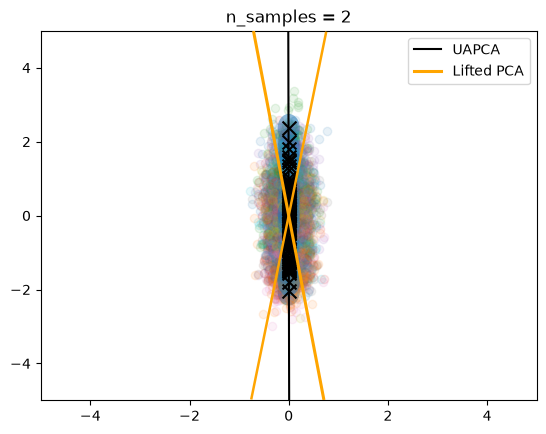

n=2 Lifted 0.02932845795419611 Distributional 0.05017746228955865
[0.49929753 0.50070247]


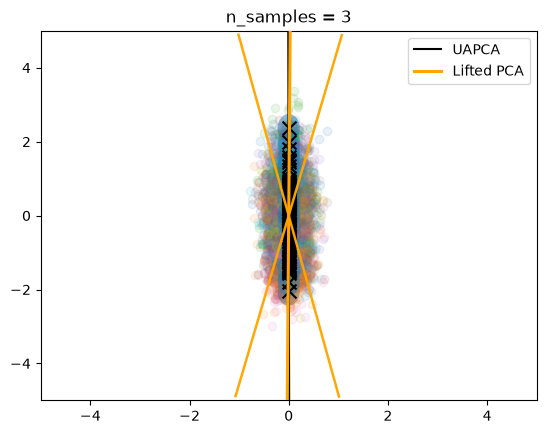

n=3 Lifted 0.02311854955145687 Distributional 0.05017746228955865
[0.33893307 0.33114488 0.32992205]


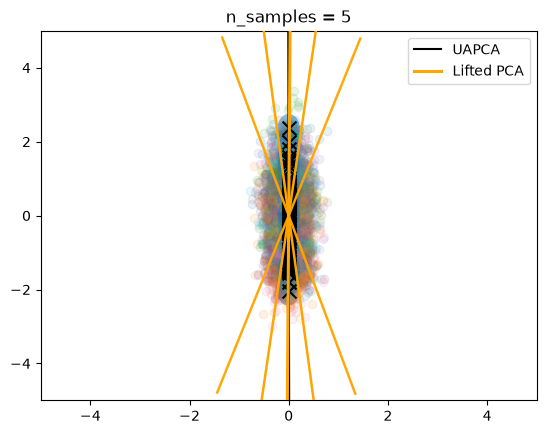

n=5 Lifted 0.018557171786411954 Distributional 0.05017746228955865
[0.19661299 0.20335534 0.20244598 0.19539166 0.20219404]


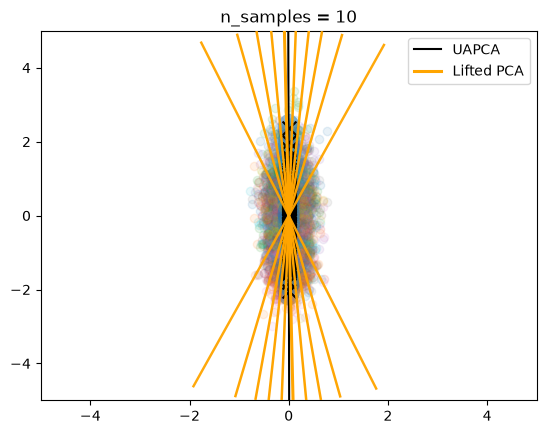

n=10 Lifted 0.01560939916462306 Distributional 0.05017746228955865
[0.10136179 0.10092815 0.10084507 0.09595511 0.09688494 0.0999417
 0.1015039  0.10128016 0.10153032 0.09976886]


In [19]:
# Vary number of Dirac, optim over weights and support
for n_samples in [1, 2, 3, 5, 10]:
    lifted_pca = LiftedPCA(n_components=1, n_samples=n_samples)
    lifted_pca.fit(samples, solver="free")
    eigenvectors_lifted = lifted_pca.components_
    
    # Distributional PCA
    pca_distributional = UAPCA()
    pca_distributional.fit_from_samples(samples)
    eigenvectors_distributional = pca_distributional.components_# .numpy()

    plot(eigenvectors_lifted, eigenvectors_distributional, samples, means, Sigmas, title="n_samples = "+str(n_samples),
        weights=lifted_pca.weights_.numpy())

    print(
        "n="+str(n_samples), "Lifted", lifted_pca.cost_barycenter(samples).item(),
        "Distributional", pca_distributional.cost_barycenter(samples).item()
    )

    print(lifted_pca.weights_.numpy())

## 2 Clear PC

In [20]:
n_distr = 100

x0 = torch.zeros((n_distr//2, 1))
x1 = torch.randn((n_distr//2, 1))
means0 = torch.concatenate([x0, x1], axis=1)
means1 = torch.concatenate([x1, x0], axis=1)
means = torch.concatenate([means0, means1], axis=0)

# Mean to center full distributions (to be equivalent with PCA)
full_mean = torch.mean(means, axis=0)

Sigma0 = torch.diag(torch.tensor([0.5, 1.5])) * 0.1
Sigma1 = torch.diag(torch.tensor([1.5, 0.5])) * 0.1
Sigmas = torch.stack([Sigma0 if i<50 else Sigma1 for i in range(len(means))])

# spd = SPDMatrices(2)
# samples = spd.random_point(n_samples=4)
# Sigmas = torch.from_numpy(samples).type(torch.float)

n = 50
d = 2
samples = torch.zeros((len(means), n, d))
for k in range(len(means)):
    samples[k] = means[k] + torch.randn(n, d) @ sqrtm(Sigmas[k])

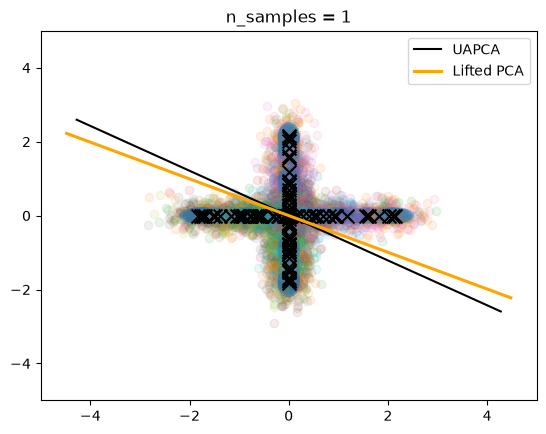

n=1 Lifted 0.6409897869355123 Distributional 0.6409202496424606


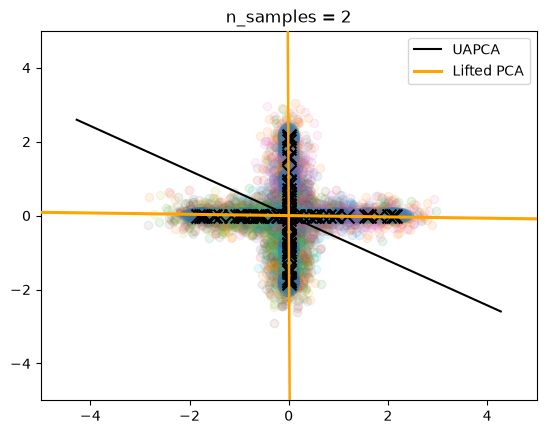

n=2 Lifted 0.37923944340251686 Distributional 0.6409202496424606


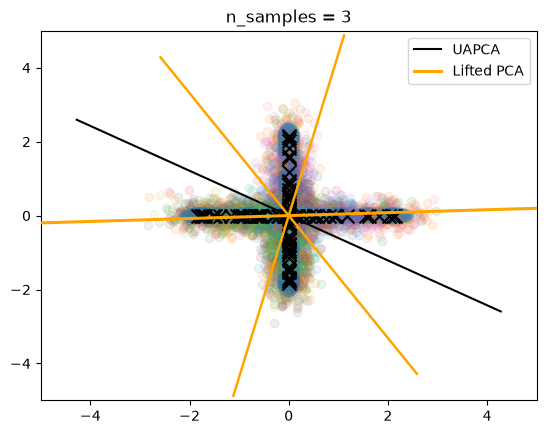

n=3 Lifted 0.36249588124189536 Distributional 0.6409202496424606


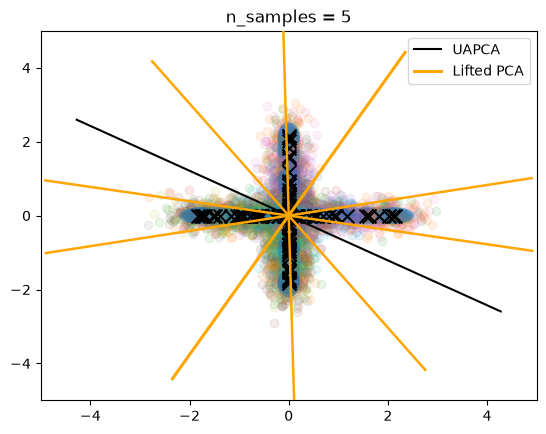

n=5 Lifted 0.33040669365554737 Distributional 0.6409202496424606


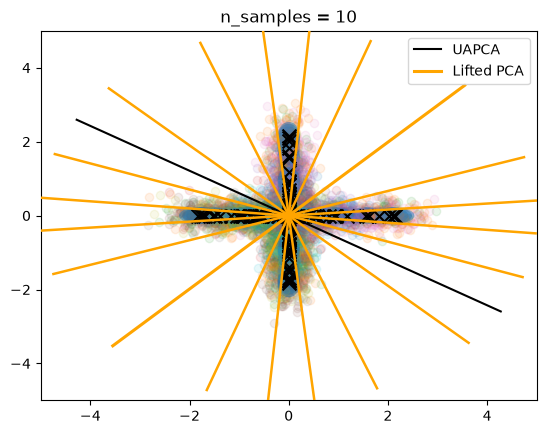

n=10 Lifted 0.3154941663321086 Distributional 0.6409202496424606


In [22]:
# Vary number of Dirac
for n_samples in [1, 2, 3, 5, 10]:
    lifted_pca = LiftedPCA(n_components=1, n_samples=n_samples)
    lifted_pca.fit(samples)
    eigenvectors_lifted = lifted_pca.components_
    
    # Distributional PCA
    pca_distributional = UAPCA()
    pca_distributional.fit_from_samples(samples)
    eigenvectors_distributional = pca_distributional.components_# .numpy()

    plot(eigenvectors_lifted, eigenvectors_distributional, samples, means, Sigmas, title="n_samples = "+str(n_samples))

    print(
        "n="+str(n_samples), "Lifted", lifted_pca.cost_barycenter(samples).item(),
        "Distributional", pca_distributional.cost_barycenter(samples).item()
    )

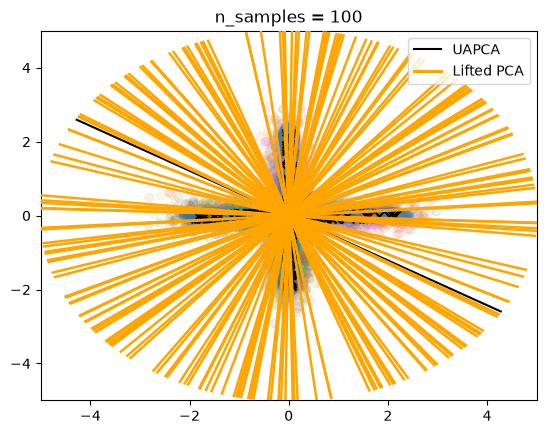

0.3215506899401126


In [23]:
# Fix the support and optim over weights only
lifted_pca = LiftedPCA(n_components=1, n_samples=100)
lifted_pca.fit(samples, solver="fixed_support", seed=42, n_iter_bary=500, stop_threshold_fixed_support=1e-20)
eigenvectors_lifted = lifted_pca.components_

# Distributional PCA
pca_distributional = UAPCA()
pca_distributional.fit_from_samples(samples)
eigenvectors_distributional = pca_distributional.components_# .numpy()

plot(eigenvectors_lifted, eigenvectors_distributional, samples, means, Sigmas,
     title="n_samples = "+str(100), weights=lifted_pca.weights_.numpy())

print(lifted_pca.cost_barycenter(samples).item())

In [24]:
lifted_pca.weights_

tensor([0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100,
        0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100,
        0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100,
        0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100,
        0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100,
        0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100,
        0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100,
        0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100,
        0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100,
        0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100,
        0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100,
        0.0100])

In [25]:
lifted_pca.weights_.max()

tensor(0.0100)

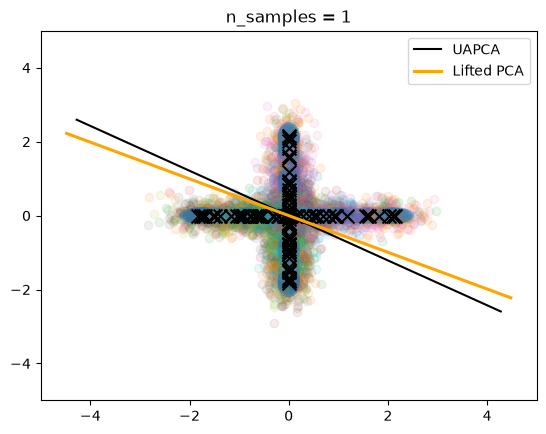

n=1 Lifted 0.6409897869355123 Distributional 0.6409202496424606
[1.]


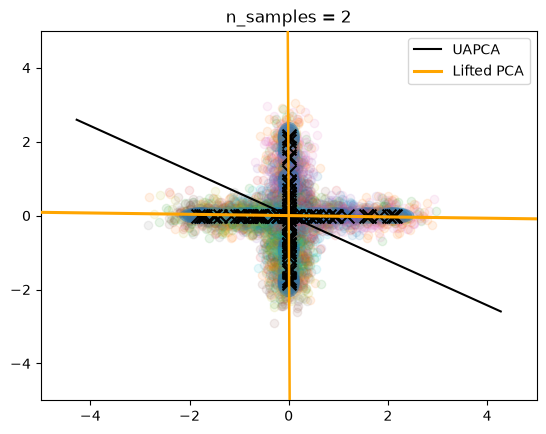

n=2 Lifted 0.37923989847858425 Distributional 0.6409202496424606
[0.50022073 0.49977927]


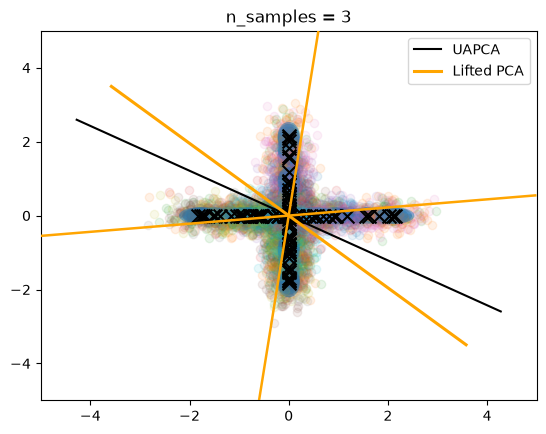

n=3 Lifted 0.3619115494346666 Distributional 0.6409202496424606
[0.33430665 0.33297515 0.3327182 ]


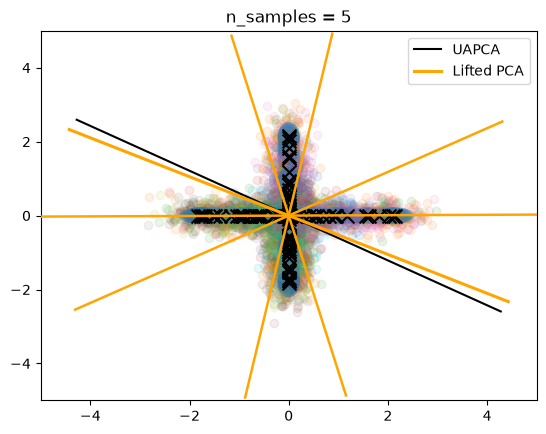

n=5 Lifted 0.330566304199929 Distributional 0.6409202496424606
[0.20037015 0.19971985 0.1997815  0.19983846 0.20029004]


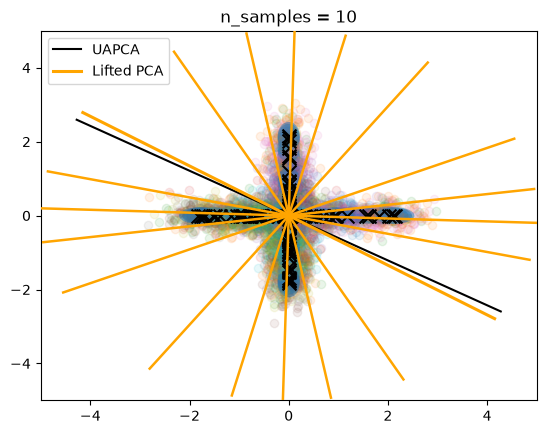

n=10 Lifted 0.3151955754426967 Distributional 0.6409202496424606
[0.09991479 0.09988483 0.10007888 0.0998134  0.09999847 0.10012973
 0.09987158 0.10015322 0.10025254 0.09990255]


In [26]:
# Vary number of Dirac, optim over weights and support
for n_samples in [1, 2, 3, 5, 10]:
    lifted_pca = LiftedPCA(n_components=1, n_samples=n_samples)
    lifted_pca.fit(samples, solver="free")
    eigenvectors_lifted = lifted_pca.components_
    
    # Distributional PCA
    pca_distributional = UAPCA()
    pca_distributional.fit_from_samples(samples)
    eigenvectors_distributional = pca_distributional.components_# .numpy()

    plot(eigenvectors_lifted, eigenvectors_distributional, samples, means, Sigmas, title="n_samples = "+str(n_samples),
        weights=lifted_pca.weights_.numpy())

    print(
        "n="+str(n_samples), "Lifted", lifted_pca.cost_barycenter(samples).item(),
        "Distributional", pca_distributional.cost_barycenter(samples).item()
    )

    print(lifted_pca.weights_.numpy())